In [1]:
import pandas as pd

# Load the dataset
df = pd.read_csv('/content/vehicle_telemetry_dataset.csv')

# Display the first 5 rows of the DataFrame
display(df.head())

,vehicle_id,record_no,operating_hours,engine_temp_C,rpm,oil_pressure_psi,vibration_mm_s,battery_voltage_V,coolant_temp_C,fuel_consumption_L100km,vehicle_speed_kmh,failure_within_100h,fault_type,remaining_useful_life_h
0,VEH001,0,10,95.02,2307.0,44.24,2.839,13.947,89.47,7.17,64.3,0,electrical,1404.0
1,VEH001,1,20,93.87,2161.0,43.65,2.640,13.952,88.30,8.06,64.2,0,electrical,1394.0
2,VEH001,2,30,95.02,2022.0,36.32,2.655,13.932,88.27,7.17,60.0,0,electrical,1384.0
3,VEH001,3,40,93.11,1914.0,41.48,2.491,14.057,86.32,6.68,58.6,0,electrical,1374.0
4,VEH001,4,50,93.32,2041.0,42.48,2.854,13.794,88.48,6.84,58.3,0,electrical,1364.0


In [2]:
# Display concise summary of the DataFrame including data types and non-null values
display(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62279 entries, 0 to 62278
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   vehicle_id               62279 non-null  object 
 1   record_no                62279 non-null  int64  
 2   operating_hours          62279 non-null  int64  
 3   engine_temp_C            62279 non-null  float64
 4   rpm                      62279 non-null  float64
 5   oil_pressure_psi         62279 non-null  float64
 6   vibration_mm_s           62279 non-null  float64
 7   battery_voltage_V        62279 non-null  float64
 8   coolant_temp_C           62279 non-null  float64
 9   fuel_consumption_L100km  62279 non-null  float64
 10  vehicle_speed_kmh        62279 non-null  float64
 11  failure_within_100h      62279 non-null  int64  
 12  fault_type               62279 non-null  object 
 13  remaining_useful_life_h  34248 non-null  float64
dtypes: float64(9), int64(3

None

In [3]:
# Calculate the percentage of missing values for each column
missing_percentage = df.isnull().sum() / len(df) * 100
print("Percentage of missing values per column:")
display(missing_percentage[missing_percentage > 0])

# Display unique values in 'fault_type' column
print("\nUnique values in 'fault_type' column:")
display(df['fault_type'].unique())

Percentage of missing values per column:


,0
remaining_useful_life_h,45.008751



Unique values in 'fault_type' column:


array(['electrical', 'none', 'oil_pump', 'cooling_system', 'bearing_wear'],
      dtype=object)

In [4]:
# Drop 'vehicle_id', 'record_no', and 'remaining_useful_life_h' as they are not needed for this classification task or have too many missing values.
df_processed = df.drop(columns=['vehicle_id', 'record_no', 'remaining_useful_life_h'])

# Perform one-hot encoding on the 'fault_type' column
df_processed = pd.get_dummies(df_processed, columns=['fault_type'], drop_first=True)

print("DataFrame after dropping columns and one-hot encoding 'fault_type':")
display(df_processed.head())

DataFrame after dropping columns and one-hot encoding 'fault_type':


,operating_hours,engine_temp_C,rpm,oil_pressure_psi,vibration_mm_s,battery_voltage_V,coolant_temp_C,fuel_consumption_L100km,vehicle_speed_kmh,failure_within_100h,fault_type_cooling_system,fault_type_electrical,fault_type_none,fault_type_oil_pump
0,10,95.02,2307.0,44.24,2.839,13.947,89.47,7.17,64.3,0,False,True,False,False
1,20,93.87,2161.0,43.65,2.640,13.952,88.30,8.06,64.2,0,False,True,False,False
2,30,95.02,2022.0,36.32,2.655,13.932,88.27,7.17,60.0,0,False,True,False,False
3,40,93.11,1914.0,41.48,2.491,14.057,86.32,6.68,58.6,0,False,True,False,False
4,50,93.32,2041.0,42.48,2.854,13.794,88.48,6.84,58.3,0,False,True,False,False


In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Initialize and train the RandomForestClassifier model
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

print("Model Training and Prediction Complete.")

# Evaluate the model
print("\nAccuracy Score:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

Model Training and Prediction Complete.

Accuracy Score: 0.9942196531791907

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00     18273
           1       0.93      0.80      0.86       411

    accuracy                           0.99     18684
   macro avg       0.96      0.90      0.93     18684
weighted avg       0.99      0.99      0.99     18684


Confusion Matrix:
 [[18247    26]
 [   82   329]]


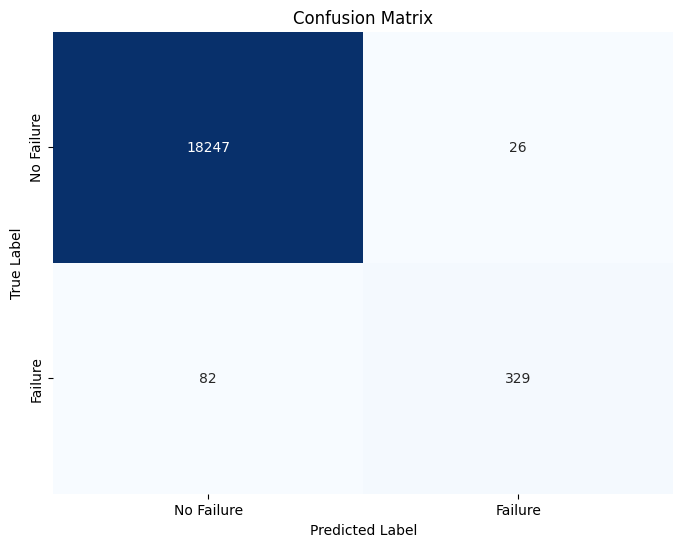

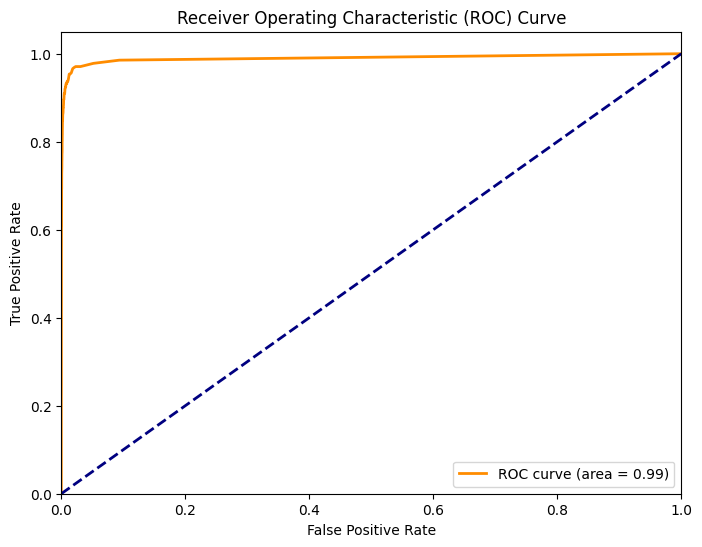

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['No Failure', 'Failure'], yticklabels=['No Failure', 'Failure'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# Plot ROC Curve
y_prob = model.predict_proba(X_test)[:, 1] # Probability of positive class
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.show()

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Define features (X) and target (y)
X = df_processed.drop('failure_within_100h', axis=1)
y = df_processed['failure_within_100h']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Identify numerical columns for scaling (exclude one-hot encoded columns which are already binary)
numerical_cols = X.select_dtypes(include=['float64', 'int64']).columns

# Initialize StandardScaler
scaler = StandardScaler()

# Scale numerical features in training and test sets
X_train[numerical_cols] = scaler.fit_transform(X_train[numerical_cols])
X_test[numerical_cols] = scaler.transform(X_test[numerical_cols])

print("Data split into training and testing sets and numerical features scaled.")
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")
display(X_train.head())

Data split into training and testing sets and numerical features scaled.
X_train shape: (43595, 13)
X_test shape: (18684, 13)
y_train shape: (43595,)
y_test shape: (18684,)


,operating_hours,engine_temp_C,rpm,oil_pressure_psi,vibration_mm_s,battery_voltage_V,coolant_temp_C,fuel_consumption_L100km,vehicle_speed_kmh,fault_type_cooling_system,fault_type_electrical,fault_type_none,fault_type_oil_pump
50772,0.227443,0.146825,-2.114194,-0.602694,0.094017,0.390716,-1.443484,-0.786966,-2.377079,False,False,False,True
60857,-0.553086,-1.312256,-0.382687,0.457313,-0.725853,-0.444196,-0.692533,-0.923569,-0.257998,False,False,False,False
7738,0.716730,1.491586,0.966311,0.580051,0.108153,0.805580,1.015380,0.541803,0.784397,False,False,True,False
55255,-0.413290,1.016257,0.096178,0.375488,-0.856216,0.369973,0.490379,-0.911150,-0.216851,False,False,True,False
2081,0.518685,0.871853,1.191144,-0.762625,-0.045769,-0.252322,-0.752344,2.615677,1.909088,False,False,True,False
